NAme : Shubh DUbey

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 120)
RANDOM_STATE = 42

## 1. Data Preprocessing

In [2]:
df = pd.read_csv("Wholesale customers data - Wholesale customers data.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [4]:
print("Missing values per column:\n", df.isnull().sum(), sep="")
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0


No missing values and no duplicate rows, so no imputation or deduplication is needed.

`Channel` and `Region` are **categorical codes**, not quantities, so we map them to readable labels for EDA. They are *not* used as clustering inputs: segmentation is based purely on purchasing behaviour. We later use `Channel` as an **external check** on whether the clusters are meaningful.

In [5]:
df["Channel_Name"] = df["Channel"].map({1: "Horeca", 2: "Retail"})
df["Region_Name"]  = df["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})

FEATURES = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df["Total_Spend"] = df[FEATURES].sum(axis=1)

display(df[FEATURES + ["Total_Spend"]].describe().round(0).astype(int))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total_Spend
count,440,440,440,440,440,440,440
mean,12000,5796,7951,3072,2881,1525,33226
std,12647,7380,9503,4855,4768,2820,26356
min,3,55,3,25,3,3,904
25%,3128,1533,2153,742,257,408,17449
50%,8504,3627,4756,1526,816,966,27492
75%,16934,7190,10656,3554,3922,1820,41308
max,112151,73498,92780,60869,40827,47943,199891


## 2. Exploratory Data Analysis (EDA)

### 2.1 Customer mix by Channel and Region

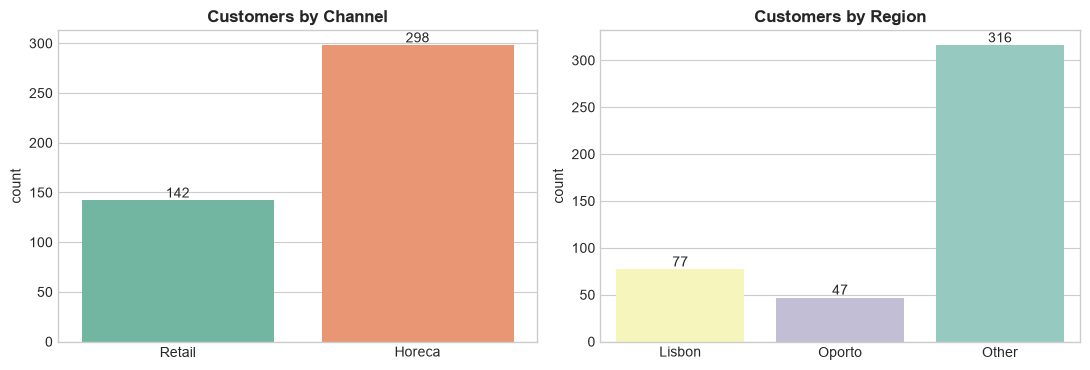

Channel_Name  Horeca  Retail  All
Region_Name                      
Lisbon            59      18   77
Oporto            28      19   47
Other            211     105  316
All              298     142  440


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(data=df, x="Channel_Name", hue="Channel_Name", ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Customers by Channel")
sns.countplot(data=df, x="Region_Name", hue="Region_Name", order=["Lisbon", "Oporto", "Other"],
              ax=axes[1], palette="Set3", legend=False)
axes[1].set_title("Customers by Region")
for ax in axes:
    for c in ax.containers: ax.bar_label(c)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(pd.crosstab(df["Region_Name"], df["Channel_Name"], margins=True))

### 2.2 Distribution of spending features

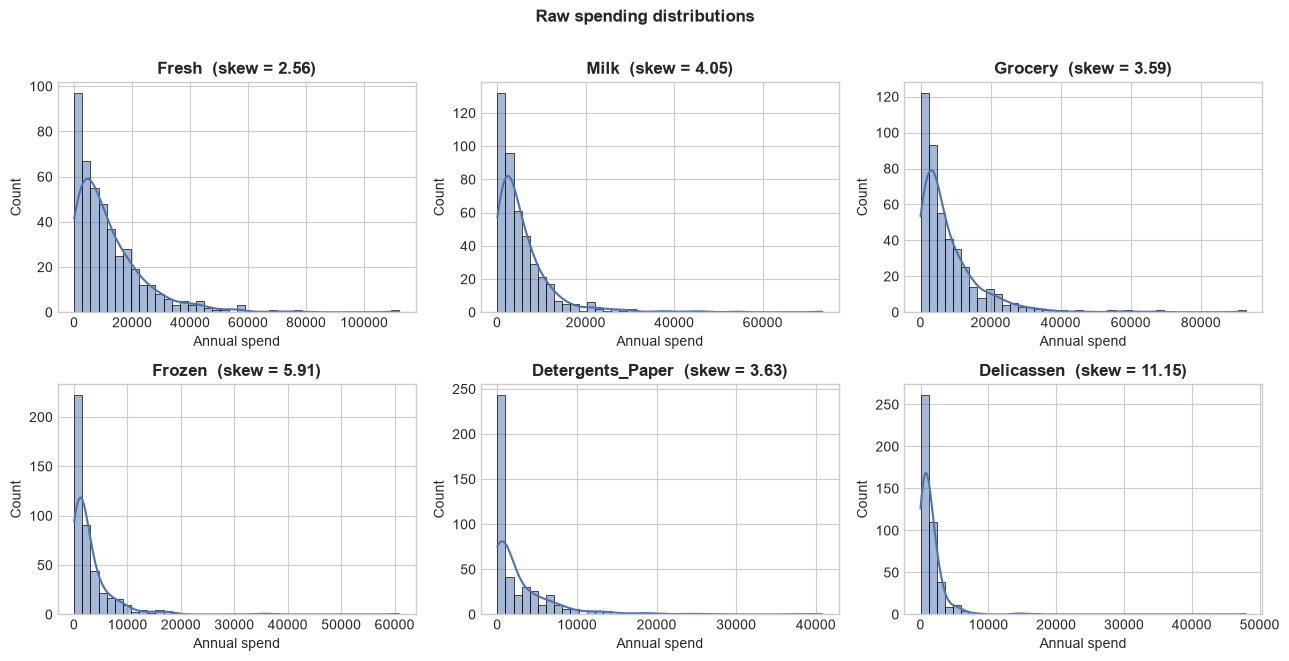

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xlabel("Annual spend")
plt.suptitle("Raw spending distributions", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

Every feature is **strongly right-skewed** (skewness 2.5–11): most customers spend modestly while a few spend enormously. Distance-based algorithms like K-Means are dominated by such extreme values, so we will handle this before clustering.

### 2.3 Outliers (box plots)

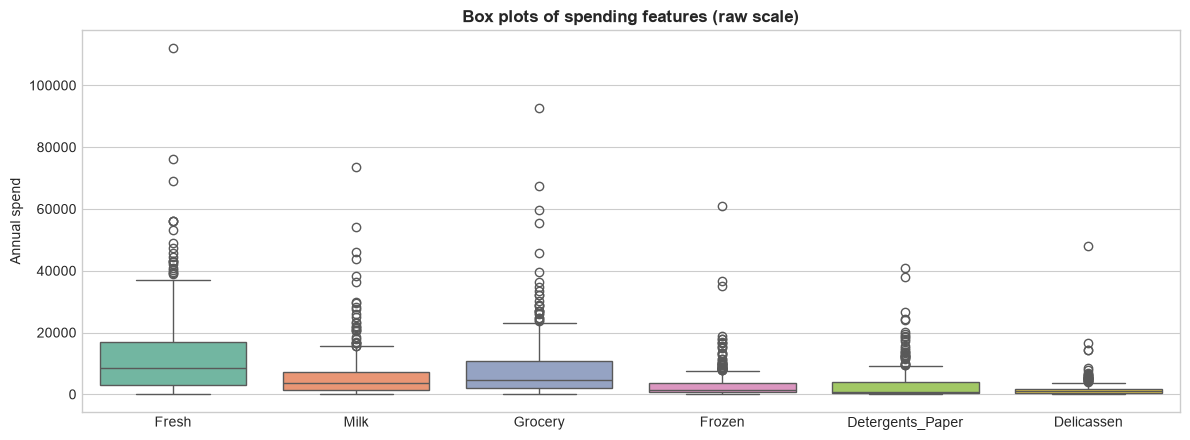

IQR outliers per feature:
Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27
dtype: int64

Customers flagged as an outlier in at least one feature: 108


In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df[FEATURES], ax=ax, palette="Set2")
ax.set_title("Box plots of spending features (raw scale)")
ax.set_ylabel("Annual spend")
plt.tight_layout(); plt.show()

Q1, Q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[FEATURES] < Q1 - 1.5 * IQR) | (df[FEATURES] > Q3 + 1.5 * IQR)
print("IQR outliers per feature:\n", outlier_mask.sum(), sep="")
print("\nCustomers flagged as an outlier in at least one feature:", outlier_mask.any(axis=1).sum())

Roughly a third of customers are an "outlier" in at least one category. These are **real, high-value customers**, not data errors, so deleting them would throw away exactly the accounts the business cares most about. Instead we apply a **log transformation**, which compresses large values and reduces their pull on the cluster centroids.

### 2.4 Correlation between categories

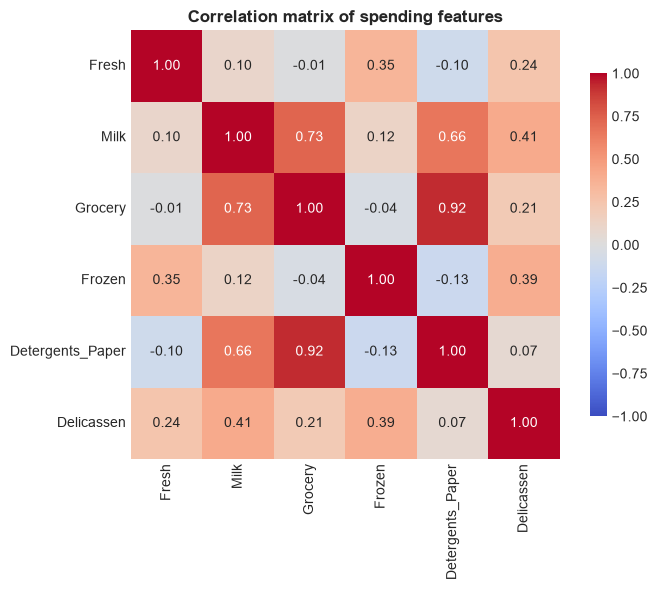

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix of spending features")
plt.tight_layout(); plt.show()

**Grocery ↔ Detergents_Paper (0.92)** and **Grocery ↔ Milk (0.73)** are highly correlated: customers who stock groceries also stock detergents/paper and milk, a typical *retail shelf* basket. **Fresh** and **Frozen** are almost uncorrelated with that group, pointing to a separate *food-service* buying pattern.

### 2.5 Spending by Channel

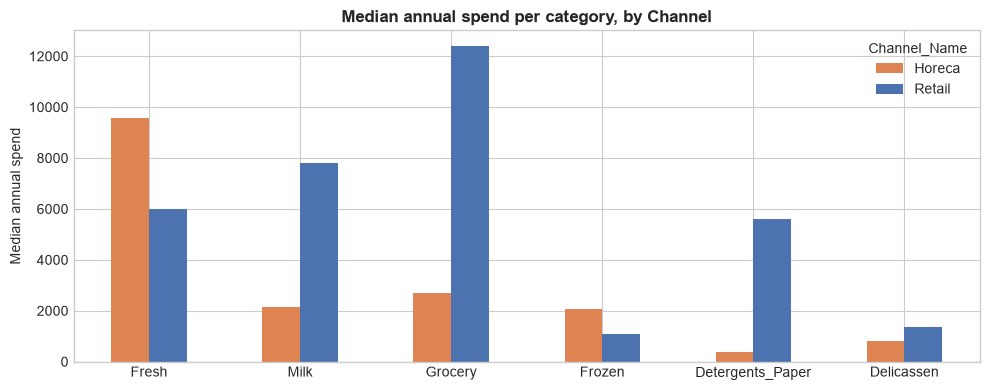

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel_Name,,,,,,
Horeca,9582,2157,2684,2058,386,821
Retail,5994,7812,12390,1081,5614,1350


In [10]:
channel_median = df.groupby("Channel_Name")[FEATURES].median()
ax = channel_median.T.plot(kind="bar", figsize=(10, 4), color=["#DD8452", "#4C72B0"], rot=0)
ax.set_title("Median annual spend per category, by Channel")
ax.set_ylabel("Median annual spend"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
display(channel_median.round(0).astype(int))

Horeca customers spend more on **Fresh and Frozen**; Retail customers spend far more on **Grocery, Milk and Detergents_Paper**. Clustering should rediscover a similar split without being told the channel.

## 3. Feature Scaling

Two steps:
1. **Log transform** `log(1 + x)`: removes the heavy right skew and tames outliers.
2. **Standardisation** (`StandardScaler`): rescales each feature to mean 0 and standard deviation 1, so no category dominates the Euclidean distance just because its spending values are larger (e.g. Fresh vs Delicassen).

In [11]:
X_log = np.log1p(df[FEATURES])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
X_scaled = pd.DataFrame(X, columns=FEATURES)

print("Skewness  before → after log transform")
print(pd.DataFrame({"raw": df[FEATURES].skew(), "log": X_log.skew()}).round(2))
print("\nAfter scaling — mean ≈ 0, std ≈ 1:")
display(X_scaled.describe().loc[["mean", "std"]].round(3))

Skewness  before → after log transform
                    raw   log
Fresh              2.56 -1.58
Milk               4.05 -0.22
Grocery            3.59 -0.67
Frozen             5.91 -0.35
Detergents_Paper   3.63 -0.24
Delicassen        11.15 -1.09

After scaling — mean ≈ 0, std ≈ 1:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
mean,0.000,-0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001


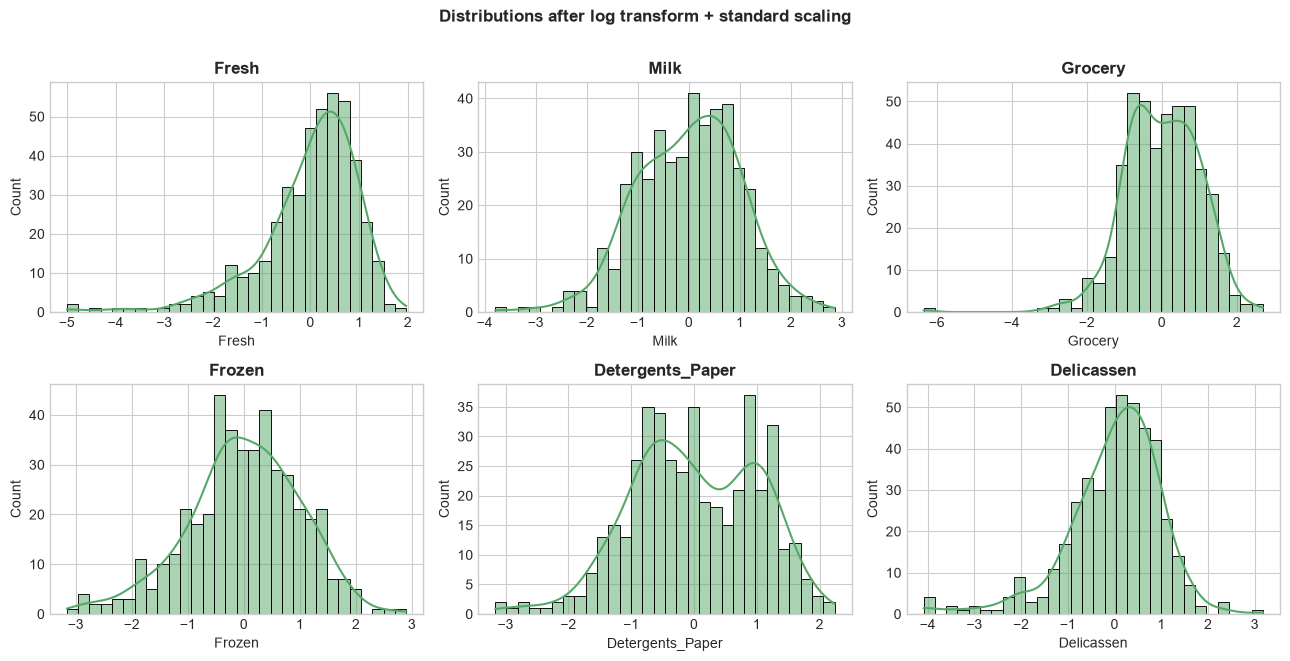

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(X_scaled[col], bins=30, kde=True, ax=ax, color="#55A868")
    ax.set_title(col)
plt.suptitle("Distributions after log transform + standard scaling", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Why the log step matters.** Here is K-Means on features that were only standard-scaled, without the log transform:

In [13]:
X_nolog = StandardScaler().fit_transform(df[FEATURES])
for k in (3, 4):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_nolog)
    print(f"k={k}: cluster sizes without log transform →", np.bincount(labels))

k=3: cluster sizes without log transform → [ 45 393   2]
k=4: cluster sizes without log transform → [110 315  10   5]


Without the log transform, K-Means wastes clusters on a handful of extreme customers (clusters of 2, 5 or 10 people), which is useless for marketing. With the log transform the clusters are balanced, as we'll see below.

## 4. Optimal Number of Clusters: Elbow Method

The **Elbow Method** plots the *Within-Cluster Sum of Squares* (WCSS, `inertia_`) against *k*. WCSS always falls as *k* grows; the "elbow" is where adding another cluster stops giving a big improvement.

To avoid picking the elbow purely by eye, we also locate it numerically: the elbow is the point on the curve **farthest from the straight line** joining the first and last points. Silhouette scores are shown alongside as a second opinion.

In [14]:
K_RANGE = range(1, 11)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_ for k in K_RANGE]
sil  = {k: silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X))
        for k in K_RANGE if k > 1}

# Elbow = point with maximum perpendicular distance from the line (k=1 → k=10)
pts = np.column_stack([list(K_RANGE), wcss]).astype(float)
pts_n = (pts - pts.min(0)) / (pts.max(0) - pts.min(0))
p1, p2 = pts_n[0], pts_n[-1]
d = p2 - p1
dist = np.abs(d[0] * (p1[1] - pts_n[:, 1]) - d[1] * (p1[0] - pts_n[:, 0])) / np.linalg.norm(d)
OPTIMAL_K = list(K_RANGE)[int(np.argmax(dist))]

print(pd.DataFrame({"k": list(K_RANGE), "WCSS": np.round(wcss, 1),
                    "Drop in WCSS": np.r_[np.nan, -np.diff(wcss)].round(1),
                    "Silhouette": [np.nan] + [round(sil[k], 3) for k in K_RANGE if k > 1]}).to_string(index=False))
print(f"\nElbow detected at k = {OPTIMAL_K}")

 k   WCSS  Drop in WCSS  Silhouette
 1 2640.0           NaN         NaN
 2 1844.1         795.9       0.290
 3 1553.4         290.6       0.259
 4 1386.9         166.6       0.188
 5 1266.1         120.7       0.192
 6 1174.8          91.4       0.201
 7 1086.4          88.4       0.196
 8 1028.5          57.9       0.185
 9  973.1          55.3       0.197
10  932.0          41.1       0.191

Elbow detected at k = 3


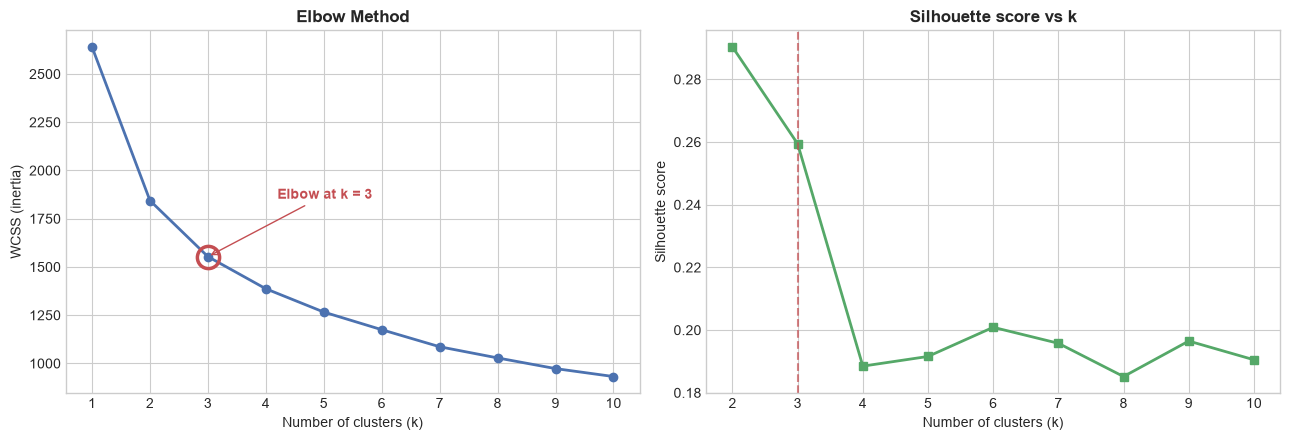

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(K_RANGE), wcss, "o-", color="#4C72B0", lw=2)
axes[0].plot(OPTIMAL_K, wcss[OPTIMAL_K - 1], "o", ms=16, mfc="none", mec="#C44E52", mew=2.5)
axes[0].annotate(f"Elbow at k = {OPTIMAL_K}", (OPTIMAL_K, wcss[OPTIMAL_K - 1]),
                 xytext=(OPTIMAL_K + 1.2, wcss[OPTIMAL_K - 1] + 300),
                 arrowprops=dict(arrowstyle="->", color="#C44E52"), color="#C44E52", fontweight="bold")
axes[0].set(title="Elbow Method", xlabel="Number of clusters (k)", ylabel="WCSS (inertia)", xticks=list(K_RANGE))

axes[1].plot(list(sil.keys()), list(sil.values()), "s-", color="#55A868", lw=2)
axes[1].axvline(OPTIMAL_K, ls="--", color="#C44E52", alpha=.7)
axes[1].set(title="Silhouette score vs k", xlabel="Number of clusters (k)", ylabel="Silhouette score",
            xticks=list(sil.keys()))
plt.tight_layout(); plt.show()

**Choice of k = 3.**
- The WCSS curve bends most sharply at **k = 3**: the drop from 1→2 and 2→3 clusters is large, while each cluster after that buys only a small, steadily shrinking improvement.
- Silhouette is highest at k = 2 and then dips slightly at k = 3, so k = 2 is marginally "cleaner" geometrically. But k = 2 only rediscovers *Horeca vs Retail*, which the business already knows from the `Channel` column. k = 3 keeps cluster quality almost unchanged while splitting retail-type customers into two commercially different groups (see Section 9).

We therefore use **k = 3** for both algorithms so they can be compared on equal terms.

## 5. K-Means Clustering

K-Means assigns each customer to the nearest of *k* centroids, then moves each centroid to the mean of its members, repeating until assignments stop changing. `k-means++` initialisation and `n_init=10` restarts guard against a poor local optimum.

In [16]:
t0 = time.perf_counter()
kmeans = KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=10, random_state=RANDOM_STATE)
km_raw_labels = kmeans.fit_predict(X)
km_time = time.perf_counter() - t0

print(f"Converged in {kmeans.n_iter_} iterations  |  WCSS = {kmeans.inertia_:.1f}  |  time = {km_time*1000:.1f} ms")
print("Cluster sizes:", np.bincount(km_raw_labels))

Converged in 11 iterations  |  WCSS = 1553.4  |  time = 30.2 ms
Cluster sizes: [ 80 147 213]


Cluster IDs (0, 1, 2) are arbitrary and differ between algorithms. To compare the two methods fairly, we give every cluster a **descriptive segment name** based on its buying profile, using the same rule for both:
- the cluster most tilted towards **Fresh + Frozen** (vs Grocery + Detergents_Paper) → *Fresh-Food Buyers*
- of the remaining two, the one with **higher overall spend** → *High-Volume All-Rounders*
- the other → *Packaged-Goods Specialists*

In [17]:
SEGMENTS = ["Fresh-Food Buyers", "High-Volume All-Rounders", "Packaged-Goods Specialists"]
PALETTE  = dict(zip(SEGMENTS, ["#DD8452", "#4C72B0", "#55A868"]))

def name_segments(labels):
    # Map arbitrary cluster ids to segment names using cluster profiles (scaled space).
    prof = X_scaled.groupby(labels).mean()
    tilt = (prof["Fresh"] + prof["Frozen"]) - (prof["Grocery"] + prof["Detergents_Paper"])
    fresh_id = tilt.idxmax()
    rest = prof.drop(index=fresh_id).sum(axis=1).sort_values(ascending=False)
    mapping = {fresh_id: SEGMENTS[0], rest.index[0]: SEGMENTS[1], rest.index[1]: SEGMENTS[2]}
    return pd.Series(labels).map(mapping).values

df["KMeans_Segment"] = name_segments(km_raw_labels)
print(df["KMeans_Segment"].value_counts().reindex(SEGMENTS))

KMeans_Segment
Fresh-Food Buyers             213
High-Volume All-Rounders      147
Packaged-Goods Specialists     80
Name: count, dtype: int64


In [18]:
centroids = pd.DataFrame(np.expm1(scaler.inverse_transform(kmeans.cluster_centers_)), columns=FEATURES)
centroids.index = pd.Series(range(OPTIMAL_K)).map(dict(zip(km_raw_labels, df["KMeans_Segment"])))
print("K-Means centroids converted back to annual spend (geometric-mean customer of each segment):")
display(centroids.reindex(SEGMENTS).round(0).astype(int))

K-Means centroids converted back to annual spend (geometric-mean customer of each segment):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh-Food Buyers,7869,1529,1985,1976,246,602
High-Volume All-Rounders,11287,7972,10520,2168,2762,1906
Packaged-Goods Specialists,1095,5635,9851,344,3392,318


## 6. Hierarchical (Agglomerative) Clustering

Agglomerative clustering starts with every customer as its own cluster and repeatedly **merges the two closest clusters** until one remains. We use **Ward linkage**, which merges the pair that causes the smallest increase in total within-cluster variance. It optimises the same objective as K-Means, so the two are directly comparable.

In [19]:
t0 = time.perf_counter()
agg = AgglomerativeClustering(n_clusters=OPTIMAL_K, metric="euclidean", linkage="ward")
agg_raw_labels = agg.fit_predict(X)
agg_time = time.perf_counter() - t0

df["Hierarchical_Segment"] = name_segments(agg_raw_labels)
print(f"time = {agg_time*1000:.1f} ms")
print(df["Hierarchical_Segment"].value_counts().reindex(SEGMENTS))

time = 7.6 ms
Hierarchical_Segment
Fresh-Food Buyers             262
High-Volume All-Rounders      125
Packaged-Goods Specialists     53
Name: count, dtype: int64


## 7. Dendrogram

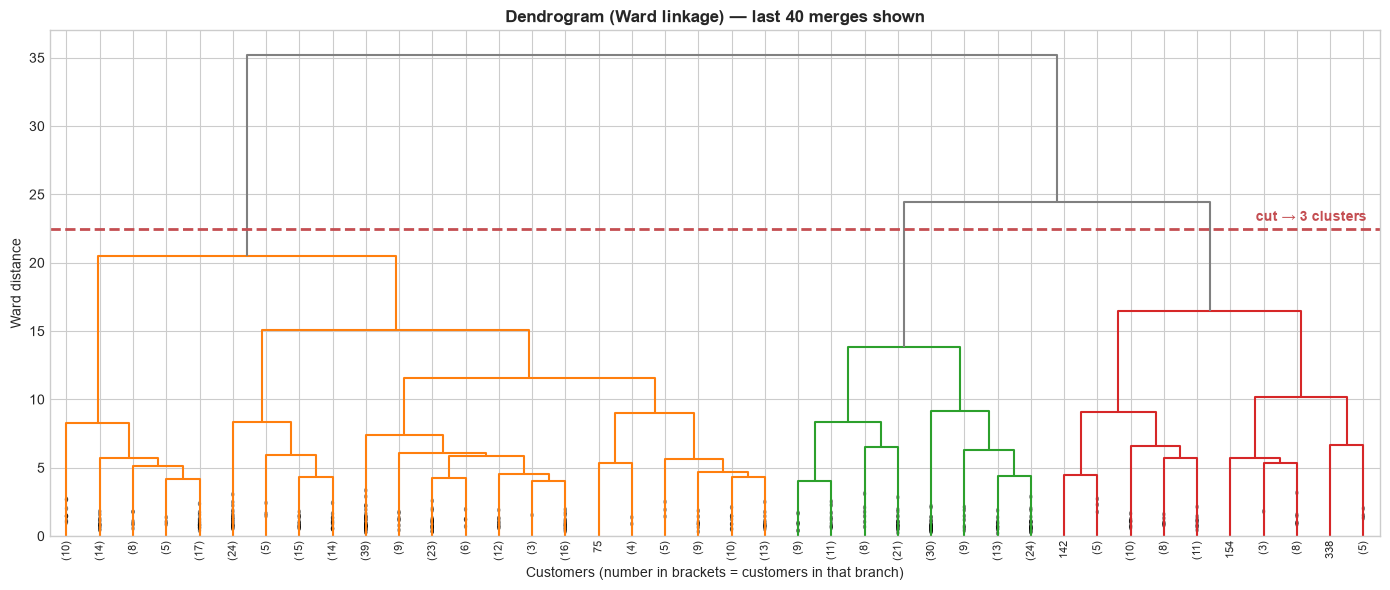

Heights of the last 5 merges: [15.1 16.5 20.5 24.5 35.2]


In [20]:
Z = linkage(X, method="ward")
cut_height = (Z[-OPTIMAL_K, 2] + Z[-OPTIMAL_K + 1, 2]) / 2   # between the last merges → k clusters

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=8,
           show_contracted=True, color_threshold=cut_height, above_threshold_color="grey", ax=ax)
ax.axhline(cut_height, ls="--", color="#C44E52", lw=2)
ax.text(ax.get_xlim()[1] * 0.99, cut_height + 0.6, f"cut → {OPTIMAL_K} clusters",
        ha="right", color="#C44E52", fontweight="bold")
ax.set(title="Dendrogram (Ward linkage) — last 40 merges shown",
       xlabel="Customers (number in brackets = customers in that branch)", ylabel="Ward distance")
plt.tight_layout(); plt.show()

print("Heights of the last 5 merges:", np.round(Z[-5:, 2], 1))

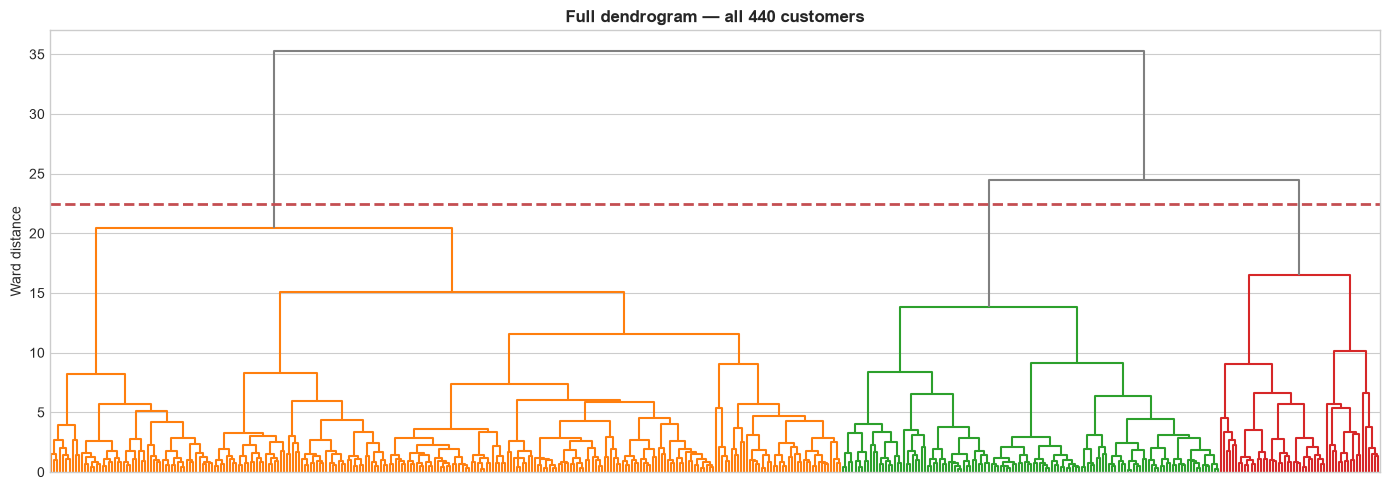

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=cut_height, above_threshold_color="grey", ax=ax)
ax.axhline(cut_height, ls="--", color="#C44E52", lw=2)
ax.set(title="Full dendrogram — all 440 customers", ylabel="Ward distance")
plt.tight_layout(); plt.show()

**Reading the dendrogram:** the vertical height of each merge is the cost of joining those two groups. The longest vertical lines without a merge are the most "natural" separations. Cutting the tree at the dashed red line crosses exactly three branches, which confirms **3 clusters** independently of the Elbow Method. The large gap between the top merge and the next one also explains why k = 2 had the best silhouette score.

## 8. Visualising Customer Segments

### 8.1 2-D PCA projection

The data has 6 dimensions, so we project it onto the first two **principal components** purely for plotting (clustering was done on all six features).

Variance explained: PC1 = 44.1%, PC2 = 27.2%  (total 71.3%)


,PC1,PC2
Fresh,-0.11,0.59
Milk,0.54,0.13
Grocery,0.57,-0.01
Frozen,-0.14,0.59
Detergents_Paper,0.55,-0.07
Delicassen,0.21,0.53


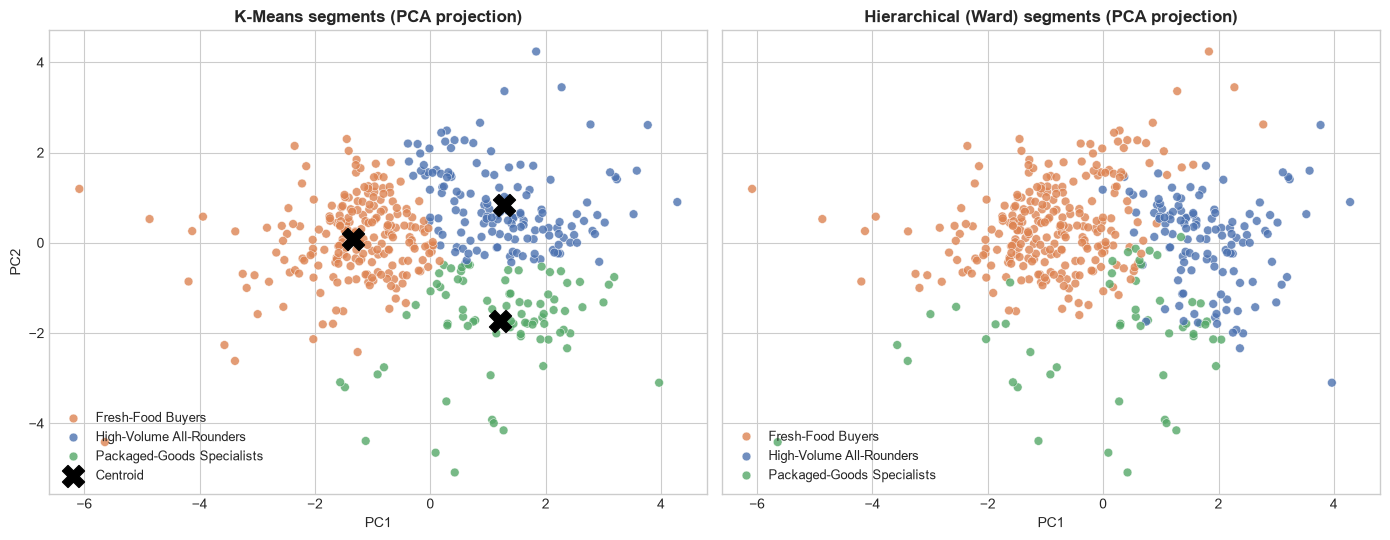

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
print(f"Variance explained: PC1 = {pca.explained_variance_ratio_[0]:.1%}, "
      f"PC2 = {pca.explained_variance_ratio_[1]:.1%}  (total {pca.explained_variance_ratio_.sum():.1%})")
display(pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2))

km_centers_2d = pca.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "KMeans_Segment", "K-Means"), (axes[1], "Hierarchical_Segment", "Hierarchical (Ward)")]:
    sns.scatterplot(data=df, x="PC1", y="PC2", hue=col, hue_order=SEGMENTS, palette=PALETTE,
                    s=40, alpha=.8, edgecolor="white", linewidth=.4, ax=ax)
    ax.set_title(f"{title} segments (PCA projection)")
    ax.legend(title="", loc="lower left", fontsize=9)
axes[0].scatter(km_centers_2d[:, 0], km_centers_2d[:, 1], marker="X", s=250, c="black", label="Centroid")
axes[0].legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

PC1 is driven by **Grocery, Detergents_Paper and Milk** (the retail basket), so it separates *Fresh-Food Buyers* (left) from the two packaged-goods-heavy segments. PC2 mainly reflects **Fresh, Frozen and Delicassen** volume, separating the *High-Volume All-Rounders* from the leaner *Packaged-Goods Specialists*.

### 8.2 Segments on the two most informative features

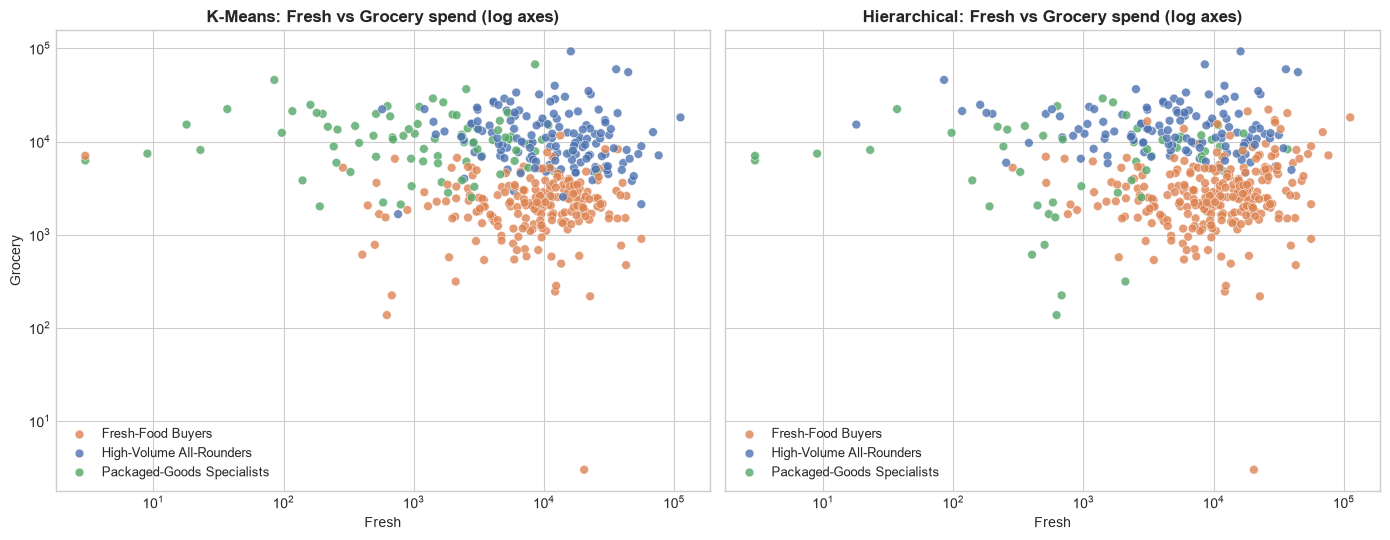

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "KMeans_Segment", "K-Means"), (axes[1], "Hierarchical_Segment", "Hierarchical")]:
    sns.scatterplot(data=df, x="Fresh", y="Grocery", hue=col, hue_order=SEGMENTS, palette=PALETTE,
                    s=40, alpha=.8, edgecolor="white", linewidth=.4, ax=ax)
    ax.set(xscale="log", yscale="log", title=f"{title}: Fresh vs Grocery spend (log axes)")
    ax.legend(title="", fontsize=9)
plt.tight_layout(); plt.show()

### 8.3 Segment profiles

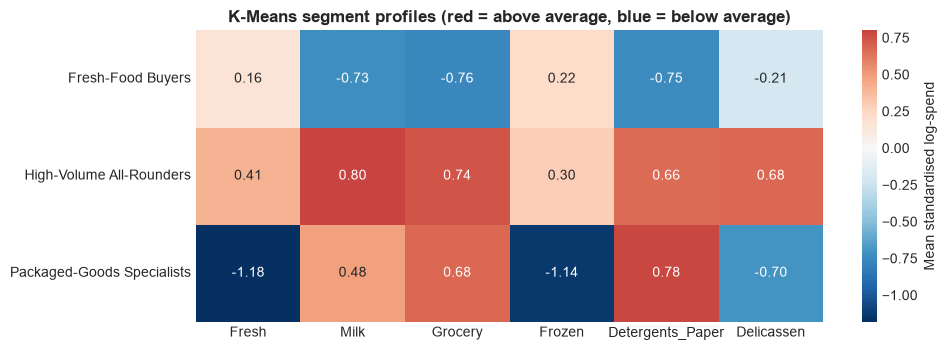

In [24]:
profile_z = X_scaled.groupby(df["KMeans_Segment"]).mean().reindex(SEGMENTS)
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(profile_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Mean standardised log-spend"})
ax.set_title("K-Means segment profiles (red = above average, blue = below average)")
ax.set_ylabel("")
plt.tight_layout(); plt.show()

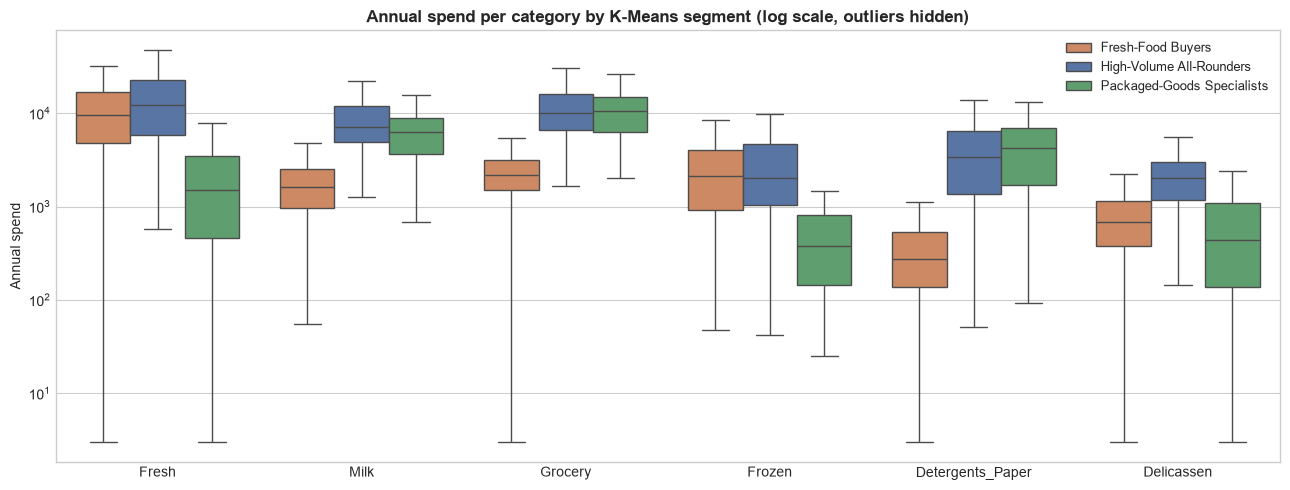

In [25]:
long = df.melt(id_vars="KMeans_Segment", value_vars=FEATURES, var_name="Category", value_name="Spend")
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=long, x="Category", y="Spend", hue="KMeans_Segment", hue_order=SEGMENTS,
            palette=PALETTE, showfliers=False, ax=ax)
ax.set(yscale="log", title="Annual spend per category by K-Means segment (log scale, outliers hidden)",
       xlabel="", ylabel="Annual spend")
ax.legend(title="", loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

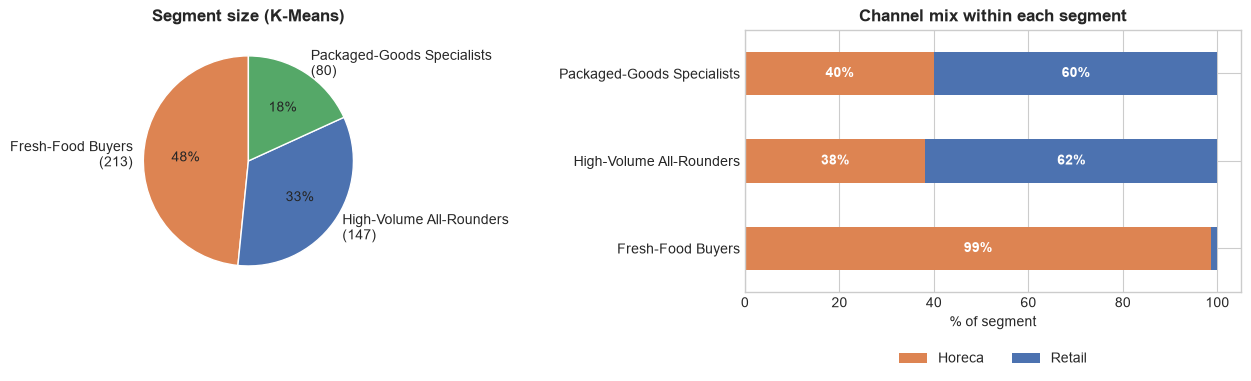

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
size = df["KMeans_Segment"].value_counts().reindex(SEGMENTS)
axes[0].pie(size, labels=[f"{s}\n({n})" for s, n in size.items()], colors=[PALETTE[s] for s in SEGMENTS],
            autopct="%1.0f%%", startangle=90, wedgeprops=dict(edgecolor="white"))
axes[0].set_title("Segment size (K-Means)")

mix = pd.crosstab(df["KMeans_Segment"], df["Channel_Name"], normalize="index").reindex(SEGMENTS) * 100
mix.plot(kind="barh", stacked=True, color=["#DD8452", "#4C72B0"], ax=axes[1])
axes[1].set(title="Channel mix within each segment", xlabel="% of segment", ylabel="")
axes[1].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
for c in axes[1].containers:
    axes[1].bar_label(c, labels=[f"{v:.0f}%" if v >= 5 else "" for v in c.datavalues],
                      label_type="center", color="white", fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Comparing K-Means and Hierarchical Clustering

Since there are no true labels, we compare the methods on **internal validity metrics** plus agreement checks:

| Metric | Measures | Better |
|---|---|---|
| Silhouette score | How well each point fits its own cluster vs the nearest other cluster (−1 to 1) | Higher |
| Davies–Bouldin index | Average similarity between each cluster and its most similar one | Lower |
| Calinski–Harabasz index | Ratio of between-cluster to within-cluster dispersion | Higher |
| WCSS | Compactness (what K-Means minimises) | Lower |
| ARI vs Channel | Agreement with the known Horeca/Retail label (external check) | Higher |

In [27]:
def wcss_of(labels):
    return sum(((X[labels == c] - X[labels == c].mean(0)) ** 2).sum() for c in np.unique(labels))

rows = {}
for name, lab, t in [("K-Means", km_raw_labels, km_time), ("Hierarchical (Ward)", agg_raw_labels, agg_time)]:
    rows[name] = {
        "Silhouette ↑":          silhouette_score(X, lab),
        "Davies–Bouldin ↓":      davies_bouldin_score(X, lab),
        "Calinski–Harabasz ↑":   calinski_harabasz_score(X, lab),
        "WCSS ↓":                wcss_of(lab),
        "ARI vs Channel ↑":      adjusted_rand_score(df["Channel"], lab),
        "Runtime (ms)":          t * 1000,
        "Cluster sizes":         ", ".join(str(n) for n in np.sort(np.bincount(lab))[::-1]),
    }
comparison = pd.DataFrame(rows).T
display(comparison.style.format({c: "{:.3f}" for c in comparison.columns[:5]} | {"Runtime (ms)": "{:.1f}"}))

print(f"Agreement between the two methods: ARI = {adjusted_rand_score(km_raw_labels, agg_raw_labels):.3f}, "
      f"same segment for {(df['KMeans_Segment'] == df['Hierarchical_Segment']).mean():.1%} of customers")

,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS ↓,ARI vs Channel ↑,Runtime (ms),Cluster sizes
K-Means,0.259,1.341,152.835,1553.421,0.350,30.2,"213, 147, 80"
Hierarchical (Ward),0.255,1.539,116.799,1720.374,0.549,7.6,"262, 125, 53"


Agreement between the two methods: ARI = 0.449, same segment for 74.8% of customers


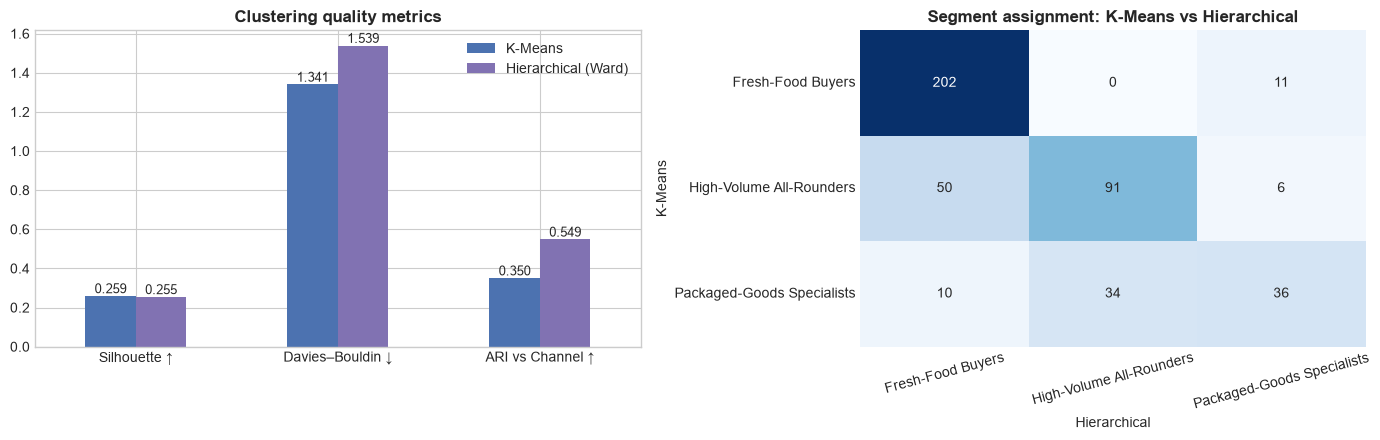

In [28]:
metrics = comparison[["Silhouette ↑", "Davies–Bouldin ↓", "ARI vs Channel ↑"]].astype(float)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
metrics.T.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#8172B2"], rot=0)
axes[0].set_title("Clustering quality metrics"); axes[0].legend(title="")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.3f", fontsize=9)

ct = pd.crosstab(df["KMeans_Segment"], df["Hierarchical_Segment"]).reindex(index=SEGMENTS, columns=SEGMENTS)
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set(title="Segment assignment: K-Means vs Hierarchical", xlabel="Hierarchical", ylabel="K-Means")
axes[1].tick_params(axis="x", rotation=15); axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

In [29]:
seg_size = pd.DataFrame({"K-Means": df["KMeans_Segment"].value_counts(),
                         "Hierarchical": df["Hierarchical_Segment"].value_counts()}).reindex(SEGMENTS)
print("Customers per segment:\n", seg_size, sep="")
print("\nMedian annual spend — Hierarchical segments:")
display(df.groupby("Hierarchical_Segment")[FEATURES].median().reindex(SEGMENTS).round(0).astype(int))

Customers per segment:
                            K-Means  Hierarchical
Fresh-Food Buyers               213           262
High-Volume All-Rounders        147           125
Packaged-Goods Specialists       80            53

Median annual spend — Hierarchical segments:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Hierarchical_Segment,,,,,,
Fresh-Food Buyers,11113,2028,2584,2382,358,864
High-Volume All-Rounders,5981,8259,12469,1148,5618,1682
Packaged-Goods Specialists,1689,4230,7854,661,2970,156


### Interpretation of the comparison

| Aspect | K-Means | Hierarchical (Ward) | Verdict |
|---|---|---|---|
| Silhouette | **0.259** | 0.255 | Practically a tie; K-Means slightly ahead |
| Davies–Bouldin | **1.34** | 1.54 | K-Means clusters are better separated |
| Calinski–Harabasz | **152.8** | 116.8 | K-Means clusters are more compact relative to spread |
| WCSS | **1553** | 1720 | Expected: K-Means directly minimises WCSS |
| ARI vs Channel | 0.35 | **0.55** | Ward's clusters line up more closely with Horeca/Retail |
| Cluster sizes | 213 / 147 / 80 | 262 / 125 / 53 | K-Means is more balanced |

**Agreement.** The methods put about **75 %** of customers in the same segment (ARI ≈ 0.45). They agree almost perfectly on the **Fresh-Food Buyers**: 202 of K-Means' 213 are in Ward's Fresh-Food group too. The differences are at the boundaries. Ward moves 50 high-Fresh customers out of K-Means' *All-Rounders* into its Fresh-Food group, so Ward's *All-Rounder* cluster becomes a smaller, more retail-dominated group (84 % Retail) with lower Fresh spend.

**Why they differ.** K-Means re-optimises every assignment until convergence, so each customer ends up nearest its centroid, giving tighter clusters on every internal metric. Ward is *greedy*: once two customers are merged early in the tree they can never be separated, so some boundary customers end up in a less-than-ideal cluster. On the other hand, that greedy, bottom-up structure follows the strongest natural divide in the data (Horeca vs Retail), which is why Ward scores higher on the Channel check.

**Practical trade-offs**

| | K-Means | Hierarchical |
|---|---|---|
| Need to choose *k* in advance | Yes (Elbow / Silhouette) | No: cut the dendrogram at any height |
| Output | Flat clusters + centroids (easy to score new customers) | Full merge tree (shows how segments nest) |
| Deterministic | Depends on initialisation (fixed with `random_state`, `n_init`) | Yes |
| Scalability | ~O(n·k·iterations): handles millions of rows | O(n²) memory: impractical beyond ~tens of thousands |
| Cluster shape | Assumes roughly spherical, similar-sized clusters | Depends on linkage; Ward also favours compact clusters |

**Conclusion of the comparison:** both methods find the same underlying 3-segment structure. **K-Means is the better choice for deployment** here: it gives better-separated, more balanced clusters, its centroids make it trivial to assign new customers to a segment, and it scales to a growing customer base. **Hierarchical clustering is the better exploratory tool**: the dendrogram confirmed k = 3 without any guessing and shows management how the segments would split if they later wanted finer targeting.

## 10. Business Insights

In [30]:
summary = df.groupby("KMeans_Segment").agg(
    Customers=("Fresh", "size"),
    Share_of_customers=("Fresh", lambda s: len(s) / len(df) * 100),
    Median_total_spend=("Total_Spend", "median"),
    Share_of_revenue=("Total_Spend", lambda s: s.sum() / df["Total_Spend"].sum() * 100),
    Retail_pct=("Channel", lambda s: (s == 2).mean() * 100),
).reindex(SEGMENTS)
display(summary.round(1))

med = df.groupby("KMeans_Segment")[FEATURES].median().reindex(SEGMENTS)
share = med.div(med.sum(axis=1), axis=0) * 100
print("\nMedian spend per category (K-Means segments):")
display(med.round(0).astype(int))
print("Basket composition — % of a typical customer's spend:")
display(share.round(1))

,Customers,Share_of_customers,Median_total_spend,Share_of_revenue,Retail_pct
KMeans_Segment,,,,,
Fresh-Food Buyers,213,48.4,18480.0,30.6,1.4
High-Volume All-Rounders,147,33.4,45833.0,53.2,61.9
Packaged-Goods Specialists,80,18.2,27484.0,16.2,60.0



Median spend per category (K-Means segments):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Segment,,,,,,
Fresh-Food Buyers,9612,1601,2155,2121,274,686
High-Volume All-Rounders,12126,7184,9965,2005,3378,2005
Packaged-Goods Specialists,1492,6300,10502,376,4218,434


Basket composition — % of a typical customer's spend:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Segment,,,,,,
Fresh-Food Buyers,58.4,9.7,13.1,12.9,1.7,4.2
High-Volume All-Rounders,33.1,19.6,27.2,5.5,9.2,5.5
Packaged-Goods Specialists,6.4,27.0,45.0,1.6,18.1,1.9


### Segment profiles and recommended actions (based on K-Means)

**1. Fresh-Food Buyers — 213 customers (48 %), ~31 % of revenue**
- Almost entirely **Horeca** (≈ 99 %): hotels, restaurants and cafés.
- About **58 %** of a typical basket is **Fresh** produce and **13 %** **Frozen**; they buy very little Grocery, Milk or Detergents_Paper.
- Lowest median total spend (≈ 18,500 units/year) but the **largest group**.
- **Actions:**
  - Compete on **freshness, quality and delivery reliability** (early-morning or daily delivery slots, guaranteed cold chain). Price discounts on packaged groceries will not move this group.
  - Offer **standing-order contracts** and volume discounts on fresh and frozen lines to lock in repeat business.
  - **Cross-sell** kitchen essentials they currently buy elsewhere (cleaning supplies, paper napkins, dairy) as add-ons to their fresh orders, since their Detergents_Paper and Milk spend is far below the other segments.

**2. High-Volume All-Rounders — 147 customers (33 %), ~53 % of revenue**
- Mixed channel (≈ 62 % Retail): large supermarkets and big food-service operators.
- **Above-average spend in every category**, including the highest Delicassen spend. Median total ≈ 45,800 units/year, about 2.5× the Fresh-Food Buyers.
- A third of the customers generate more than half of the revenue: **this is the segment to protect**.
- **Actions:**
  - Put them in a **premium loyalty tier**: dedicated account manager, priority stock allocation, tiered rebates based on annual spend.
  - Promote **premium and delicatessen ranges** and new product launches here first; they already buy across the whole catalogue.
  - Monitor for **churn signals** (falling order frequency or value), since losing one of these customers costs far more than losing one from any other segment.

**3. Packaged-Goods Specialists — 80 customers (18 %), ~16 % of revenue**
- Mostly **Retail** (≈ 60 %): smaller grocery stores and convenience shops.
- About **90 %** of a typical basket is **Grocery, Milk and Detergents_Paper**; they buy almost no Fresh (6 %) or Frozen (2 %).
- **Actions:**
  - Run **bundled promotions** on grocery + dairy + household/paper products ("shelf-filler" bundles) and bulk-buy discounts on fast-moving packaged lines.
  - **Growth opportunity:** introduce small, easy-to-manage **fresh and chilled ranges** (pre-packed produce, ready-to-sell frozen items). Converting part of this segment towards the All-Rounder profile is the biggest upsell lever in the dataset.
  - Use **points-based loyalty** (points per order, redeemable for free delivery or stock) to drive order frequency.

### Cross-segment observations
- **Region does not drive segmentation:** each segment is roughly 15–19 % Lisbon, 8–13 % Oporto and 69–77 % Other, close to the overall customer mix. Campaigns can therefore be designed **by segment, not by region**.
- **Channel alone is not enough:** Retail customers split into two very different groups (All-Rounders vs Packaged-Goods Specialists), with roughly a 1.7× gap in median spend. Treating all Retail customers the same would under-serve the high-value ones and over-spend on the smaller ones.
- **Next steps:** add behavioural features (order frequency, recency, margin per customer) to build an RFM-style segmentation, and re-run the clustering periodically so customers who move between segments get the right offers.

## Conclusion
- After **log transformation and standard scaling**, both algorithms find balanced, interpretable segments. Without the log step, K-Means wastes clusters on a few extreme customers.
- The **Elbow Method** and the **dendrogram** independently point to **3 segments**.
- **K-Means and Ward hierarchical clustering** agree on the overall structure (the Fresh-Food segment especially), with K-Means producing slightly better-separated clusters and scaling far better to large customer bases. Hierarchical clustering adds value through the dendrogram, which shows *how* segments nest and lets management choose a coarser or finer segmentation without re-running the model.
- The resulting segments map directly onto actionable strategies: freshness and reliability for food-service clients, volume-tier loyalty for high-value all-rounders, and bundled packaged-goods promotions plus cross-selling for smaller shops.